# Store Sales — Exploratory Data Analysis

**Kaggle: Store Sales — Time Series Forecasting**

This notebook explores daily retail sales across stores and product families, with a focus on data quality, temporal coverage, trends, weekly seasonality, and the association between promotions and sales. It also verifies that the competition test set is consistent with the historical data.

**Forecasting unit:** one daily observation per `(store_nbr, family)` combination. The `sales` column is the target; `id` is a row identifier.

> This is exploratory analysis, not a forecasting evaluation. Model validation will use a chronological split rather than random sampling.

## 1. Historical training data

### 1.1 Load and inspect

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [4]:
data_path = Path("../data/raw/train.csv")
df = pd.read_csv(data_path)

In [5]:
# Display shape (rows and columns) of the dataset
rows, cols = df.shape
print(f"Dataset contains {rows} rows and {cols} columns")

Dataset contains 3000888 rows and 6 columns


In [6]:
# Inspect original column types and non-null counts
print("Training dataset: columns, non-null counts and data types")
df.info(show_counts=True)

Training dataset: columns, non-null counts and data types
<class 'pandas.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   id           3000888 non-null  int64  
 1   date         3000888 non-null  str    
 2   store_nbr    3000888 non-null  int64  
 3   family       3000888 non-null  str    
 4   sales        3000888 non-null  float64
 5   onpromotion  3000888 non-null  int64  
dtypes: float64(1), int64(3), str(2)
memory usage: 137.4 MB


The date field is initially read as a string. Convert it to datetime before assessing calendar coverage or time-dependent patterns.

In [8]:
# Convert 'date' column to proper pandas datetime object using pd.to_datetime(), coercing errors
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Verify conversion and check for NaT values
print("Date dtype:", df["date"].dtype)
print("Invalid dates:", df["date"].isna().sum())

Date dtype: datetime64[us]
Invalid dates: 0


In [9]:
# Display first 5 rows of the dataset
df.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


### 1.2 Calendar coverage

In [11]:
# Display date range (min and max dates)
min_date, max_date = df["date"].min(), df["date"].max()
print(f"Date range: {min_date:%Y-%m-%d} to {max_date:%Y-%m-%d}")

# Display date difference in days
date_diff_days = (max_date - min_date).days + 1
print(f"Expected calendar days: {date_diff_days}")

# Display number of unique observed dates
unique_dates = df["date"].nunique()
print(f"Observed unique dates: {unique_dates}")

# Display number of days missing (vs expected for the date range)
n_missing_dates = date_diff_days - unique_dates
print(f"Dataset is missing {n_missing_dates} days from the calendar range")

Date range: 2013-01-01 to 2017-08-15
Expected calendar days: 1688
Observed unique dates: 1684
Dataset is missing 4 days from the calendar range


In [12]:
# Find calendar dates absent from the historical dataset
expected_dates = pd.date_range(min_date, max_date, freq="D")
missing_dates = expected_dates.difference(pd.DatetimeIndex(df["date"].unique()))
print([date.strftime("%Y-%m-%d") for date in missing_dates])

['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25']


**Finding.** The series spans **1,688 calendar days** but includes records for **1,684 dates**. The four absent dates are December 25 in 2013–2016. This is a systematic calendar gap, possibly associated with Christmas closures or reporting, rather than evidence of zero recorded sales. Missing dates should not be filled automatically without a justified assumption.

### 1.3 Missing values and record uniqueness

In [15]:
# Display number of missing values in the dataset
df.isna().sum()

id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

In [16]:
# A store-family pair should have at most one record on a given date
n_duplicate_keys = df.duplicated(subset=["date", "store_nbr", "family"]).sum()
print(f"Duplicate date/store/family keys: {n_duplicate_keys}")

Duplicate date/store/family keys: 0


**Finding.** No columns contain null values, and `(date, store_nbr, family)` uniquely identifies each historical observation.

### 1.4 Target distribution

In [19]:
df["sales"].describe().round(2)

count    3000888.00
mean         357.78
std         1102.00
min            0.00
25%            0.00
50%           11.00
75%          195.85
max       124717.00
Name: sales, dtype: float64

The sales distribution is highly right-skewed: the median is **11**, compared with a mean of **357.78**. High-volume observations substantially influence the mean, but should not be treated as erroneous outliers without further investigation. Recorded sales are nonnegative.

In [21]:
# Count and share of zero-sales observations
count_of_zero_sales = df["sales"].eq(0).sum()
pct_of_zero_sales = df["sales"].eq(0).mean() * 100
print(f"Zero-sales observations: {count_of_zero_sales:,} ({pct_of_zero_sales:.1f}%)")

Zero-sales observations: 939,130 (31.3%)


Approximately **31.3%** of historical rows have recorded sales of zero. These observations are distinct from the entirely missing Christmas dates.

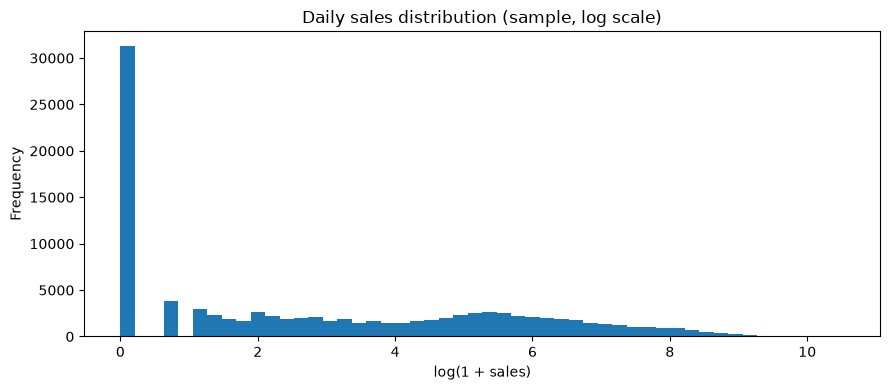

In [23]:
# Log transform is used only to make the plot readable; sales are not modified
sample = df["sales"].sample(n=100_000, random_state=42)
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(np.log1p(sample), bins=50)
ax.set(xlabel="log(1 + sales)", ylabel="Frequency", title="Daily sales distribution (sample, log scale)")
plt.tight_layout()
plt.show()

The zero-sales spike remains prominent after log transformation, alongside a broad distribution of positive sales. This suggests substantial variation between stores and product families. The plot uses a fixed-seed sample of 100,000 rows for efficiency.

### 1.5 Panel structure: stores and families

In [26]:
number_of_unique_stores = df["store_nbr"].nunique()
print(f"Number of unique stores: {number_of_unique_stores}")

Number of unique stores: 54


In [27]:
number_of_unique_families = df["family"].nunique()
print(f"Number of unique families: {number_of_unique_families}")

Number of unique families: 33


In [28]:
observed_combinations = (
    df[["store_nbr", "family"]]
    .drop_duplicates()
    .shape[0]
)

print(f"Observed store-family combinations: {observed_combinations}")

Observed store-family combinations: 1782


In [29]:
series_counts = df.groupby(["store_nbr", "family"]).size()

print(series_counts.describe())
print(f"All series have equal length: {series_counts.nunique() == 1}")

count    1782.0
mean     1684.0
std         0.0
min      1684.0
25%      1684.0
50%      1684.0
75%      1684.0
max      1684.0
dtype: float64
All series have equal length: True


**Finding.** All **54 × 33 = 1,782** store–family combinations appear in the data. Each has **1,684 records**, with identical observed dates and the same four calendar gaps. The panel is balanced over the *observed* dates, but it is not a continuous daily calendar.

### 1.6 Aggregate sales trend and weekly seasonality

In [32]:
sales_by_date = df.groupby("date", as_index=False).agg(
    total_sales=("sales", "sum")
)

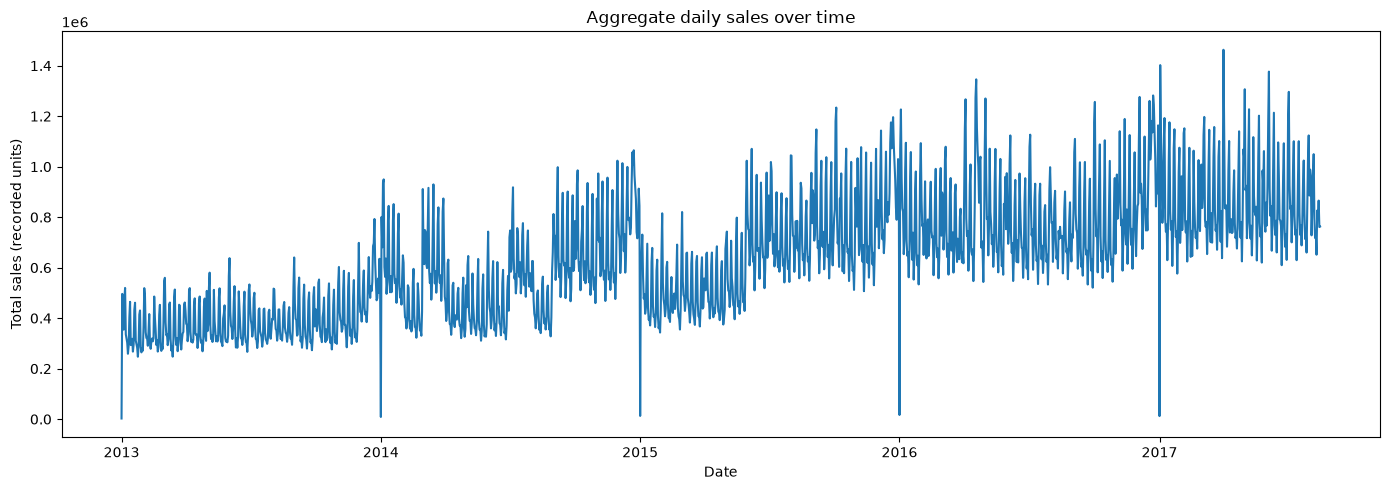

In [33]:
fig, ax = plt.subplots(figsize=(14, 5))
sns.lineplot(data=sales_by_date, x="date", y="total_sales", ax=ax)
ax.set(xlabel="Date", ylabel="Total sales (recorded units)", title="Aggregate daily sales over time")
plt.tight_layout()
plt.show()

Aggregate sales generally rise over 2013–2017, with recurring short-term fluctuations and periods of stronger sales. The scale of fluctuations appears to grow with total sales. Apparent year-end drops require care: December 25 is missing rather than recorded as zero.

In [35]:
sales_by_date["week_day_name"] = sales_by_date["date"].dt.day_name()

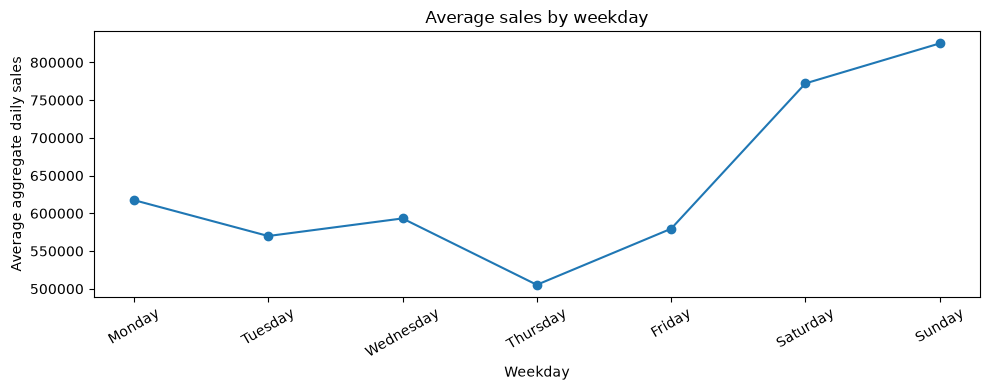

In [36]:
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

sales_by_date["week_day_name"] = pd.Categorical(
    sales_by_date["week_day_name"], categories=weekday_order, ordered=True
)

# Aggregate to one average per weekday rather than display individual daily observations
weekday_means = (
    sales_by_date.groupby("week_day_name", observed=True)["total_sales"]
    .mean()
    .reindex(weekday_order)
)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(weekday_means.index, weekday_means.values, marker="o")
ax.set(xlabel="Weekday", ylabel="Average aggregate daily sales", title="Average sales by weekday")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

Weekly seasonality is visible: average aggregate sales are generally lower Tuesday–Thursday, increase into the weekend, and peak on Sunday. These differences support including weekday information in later forecasting experiments.

### 1.7 Promotions and sales

In [39]:
df[["sales", "onpromotion"]].corr()

,sales,onpromotion
sales,1.000000,0.427923
onpromotion,0.427923,1.000000


The Pearson correlation between `onpromotion` (number of promoted items) and `sales` is **r = 0.428**. This is a moderate positive *association*, not an estimate of the causal effect of promotions.

In [41]:
# Compare rows with no items on promotion against rows with at least one
avg_not_promo_sales = df.loc[df["onpromotion"].eq(0), "sales"].mean()
print(f"Average sales (onpromotion = 0): {avg_not_promo_sales:.2f}")

Average sales (onpromotion = 0): 158.25


In [42]:
avg_on_promo_sales = df.loc[df["onpromotion"].gt(0), "sales"].mean()
print(f"Average sales (onpromotion > 0): {avg_on_promo_sales:.2f}")
print(f"Ratio: {avg_on_promo_sales / avg_not_promo_sales:.2f}x")

Average sales (onpromotion > 0): 1137.69
Ratio: 7.19x


Rows with at least one promoted item average **1,137.69** in sales, versus **158.25** with no promoted items (about **7.2×**). This comparison is descriptive: high-volume stores or families may both run more promotions and record more sales. `onpromotion` is a count, not just a binary indicator.

## 2. Forecast-period test data

The test set provides features for the forecast horizon but not the target `sales`. Checks below verify schema compatibility, complete series coverage, temporal continuity, and submission IDs.

In [45]:
test_path = Path("../data/raw/test.csv")
test_df = pd.read_csv(test_path)

In [46]:
# Display shape (rows and columns) of the dataset
rows, cols = test_df.shape
print(f"Dataset contains {rows} rows and {cols} columns")

Dataset contains 28512 rows and 5 columns


In [47]:
print("Test dataset: columns, non-null counts and data types")
test_df.info(show_counts=True)

Test dataset: columns, non-null counts and data types
<class 'pandas.DataFrame'>
RangeIndex: 28512 entries, 0 to 28511
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   id           28512 non-null  int64
 1   date         28512 non-null  str  
 2   store_nbr    28512 non-null  int64
 3   family       28512 non-null  str  
 4   onpromotion  28512 non-null  int64
dtypes: int64(3), str(2)
memory usage: 1.1 MB


In [48]:
# Display first 5 rows of the dataset
test_df.head()

,id,date,store_nbr,family,onpromotion
0,3000888,2017-08-16,1,AUTOMOTIVE,0
1,3000889,2017-08-16,1,BABY CARE,0
2,3000890,2017-08-16,1,BEAUTY,2
3,3000891,2017-08-16,1,BEVERAGES,20
4,3000892,2017-08-16,1,BOOKS,0


As in training, convert the `date` column to datetime and confirm that no invalid values result.

In [50]:
# Convert 'date' column to proper pandas datetime object using pd.to_datetime(), coercing errors
test_df["date"] = pd.to_datetime(test_df["date"], errors="coerce")

# Verify conversion and check for NaT values
print("Date dtype:", test_df["date"].dtype)
print("Invalid dates:", test_df["date"].isna().sum())

Date dtype: datetime64[us]
Invalid dates: 0


### 2.1 Forecast horizon and data quality

In [52]:
# Display date range (min and max dates)
test_min_date, test_max_date = test_df["date"].min(), test_df["date"].max()
print(f"Date range: {test_min_date:%Y-%m-%d} to {test_max_date:%Y-%m-%d}")

# Display date difference in days
test_date_diff_days = (test_max_date - test_min_date).days + 1
print(f"Expected calendar days: {test_date_diff_days}")

# Display number of unique observed dates
test_unique_dates = test_df["date"].nunique()
print(f"Observed unique dates: {test_unique_dates}")

# Display number of days missing (vs expected for the date range)
test_n_missing_dates = test_date_diff_days - test_unique_dates
print(f"Dataset is missing {test_n_missing_dates} days from the calendar range")

Date range: 2017-08-16 to 2017-08-31
Expected calendar days: 16
Observed unique dates: 16
Dataset is missing 0 days from the calendar range


In [53]:
# Display number of missing values in the dataset
test_df.isna().sum()

id             0
date           0
store_nbr      0
family         0
onpromotion    0
dtype: int64

In [54]:
n_test_duplicate_keys = test_df.duplicated(subset=["date", "store_nbr", "family"]).sum()
print(f"Duplicate date/store/family keys in test: {n_test_duplicate_keys}")

Duplicate date/store/family keys in test: 0


**Finding.** Test spans **August 16–31, 2017 (16 consecutive days)**, with no missing values, invalid dates, missing calendar days, or duplicate store–family–date keys.

### 2.2 Feature schema and series coverage

In [57]:
# Verify that test contains the same predictor columns as train
feature_columns = set(df.columns) - {"id", "sales"}
test_features = set(test_df.columns) - {"id", "sales"}

missing_features = feature_columns - test_features
unexpected_features = test_features - feature_columns

assert not missing_features, f"Missing features: {missing_features}"
assert not unexpected_features, f"Unexpected features: {unexpected_features}"

In [58]:
number_of_unique_stores_in_test = test_df["store_nbr"].nunique()
number_of_unique_families_in_test = test_df["family"].nunique()
print(f"Stores in test: {number_of_unique_stores_in_test}")
print(f"Families in test: {number_of_unique_families_in_test}")

Stores in test: 54
Families in test: 33


In [59]:
train_series = pd.MultiIndex.from_frame(df[["store_nbr", "family"]].drop_duplicates())
test_series = pd.MultiIndex.from_frame(test_df[["store_nbr", "family"]].drop_duplicates())

print(f"Store-family combinations in test: {len(test_series)}")
assert len(test_series) == 1_782
assert train_series.difference(test_series).empty, "Training series missing from test"
assert test_series.difference(train_series).empty, "Unexpected test series"

Store-family combinations in test: 1782


All expected predictor columns and **1,782 store–family combinations** appear in the test set. The series membership checks compare actual combinations, not just counts.

### 2.3 Train–test continuity and submission alignment

In [62]:
# Verify that the forecast period begins on the next calendar day
print(f"Last training day: {max_date:%Y-%m-%d}")
print(f"First test day: {test_min_date:%Y-%m-%d}")
assert test_min_date == max_date + pd.Timedelta(days=1), "Gap or overlap between train and test"
print("Train and test periods are consecutive")

Last training day: 2017-08-15
First test day: 2017-08-16
Train and test periods are consecutive


In [63]:
# Verify that the submission template contains the same IDs in the same order
submission_path = Path("../data/raw/sample_submission.csv")
submission = pd.read_csv(submission_path)

assert len(test_df) == len(submission), "Test and submission row counts differ"
assert test_df["id"].reset_index(drop=True).equals(
    submission["id"].reset_index(drop=True)
), "Submission IDs differ from test IDs or are out of order"
print("Submission IDs and row counts match test.csv")

Submission IDs and row counts match test.csv


**Finding.** The test period follows the training period without a gap or overlap. The submission template matches the test set in row count and ID order. The published forecast horizon is **16 days**, so chronological validation should simulate a 16-day forecast when comparing models.

## 3. Summary and modeling implications

- **Panel:** 1,782 store–family series, each with 1,684 historical observations.
- **Calendar:** Four missing December 25 dates. Calendar lags must use actual date arithmetic rather than assuming every preceding row is the prior day.
- **Target:** Strongly right-skewed sales with about 31.3% zero observations. Simple global averages are unlikely to fit all series well.
- **Patterns:** Aggregate sales trend upward, with clear weekday effects.
- **Promotions:** Associated with higher sales, but differences may be confounded by store and product family.
- **Forecast setup:** Predict sales for 16 consecutive days (August 16–31, 2017). The matching validation window should be held out chronologically, and sales-derived features must only use information available at forecast creation.

**Remaining EDA:** inspect the supplementary `stores.csv`, `holidays_events.csv`, `oil.csv`, and `transactions.csv` files before deciding whether and how to incorporate them. They have **not** been reviewed in this notebook.

**Next modeling step:** establish naive and seasonal-naive baselines using a time-ordered validation split, then compare increasingly complex models under the same evaluation protocol.

In [66]:
# Helper function to quickly inspect datasets
def quick_df_inspection(df):
    # Display shape (rows and columns) of the dataset
    print("--- Shape of the dataset ---")
    rows, cols = df.shape
    print(f"Dataset contains {rows} rows and {cols} columns")
    
    print()
    
    # Inspect original column types and non-null counts
    print("--- Column names, non-null counts and data types ---")
    print("Dataset: columns, non-null counts and data types")
    df.info(show_counts=True)
    
    print()
    
    # Print count of missing values in the df
    print("--- Count of missing values per column ---")
    print(df.isna().sum())

In [67]:
# Store characteristics
stores_path = Path("../data/raw/stores.csv")
stores_df = pd.read_csv(stores_path)

In [68]:
quick_df_inspection(stores_df)

--- Shape of the dataset ---
Dataset contains 54 rows and 5 columns

--- Column names, non-null counts and data types ---
Dataset: columns, non-null counts and data types
<class 'pandas.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   store_nbr  54 non-null     int64
 1   city       54 non-null     str  
 2   state      54 non-null     str  
 3   type       54 non-null     str  
 4   cluster    54 non-null     int64
dtypes: int64(2), str(3)
memory usage: 2.2 KB

--- Count of missing values per column ---
store_nbr    0
city         0
state        0
type         0
cluster      0
dtype: int64


In [69]:
# Verify store_nbr is unique
stores_df["store_nbr"].duplicated().sum()

np.int64(0)

In [70]:
store_nbr_train = set(df["store_nbr"])
store_nbr_stores = set(stores_df["store_nbr"])

missing_stores = store_nbr_train - store_nbr_stores

extra_stores = store_nbr_stores - store_nbr_train

assert not missing_stores, f"Missing stores: {missing_stores}"
assert not extra_stores, f"Extra stores: {extra_stores}"

In [71]:
# Distribution of stores by city
print("Distribution of stores by city")
print()
stores_df["city"].value_counts().to_frame()

Distribution of stores by city



,count
city,
Quito,18
Guayaquil,8
Santo Domingo,3
Cuenca,3
Latacunga,2
Ambato,2
Machala,2
Manta,2
Cayambe,1


In [72]:
# Distribution of stores by state
print("Distribution of stores by state")
print()
stores_df["state"].value_counts().to_frame()

Distribution of stores by state



,count
state,
Pichincha,19
Guayas,11
Santo Domingo de los Tsachilas,3
Azuay,3
Manabi,3
Cotopaxi,2
Tungurahua,2
Los Rios,2
El Oro,2


The retail network exhibits a notable geographic concentration. Quito and Guayaquil account for approximately 48% of all stores, while their respective provinces, Pichincha and Guayas, represent approximately 56%. The remaining stores are distributed across smaller cities and provinces, suggesting that geographic characteristics may be relevant predictors of sales patterns.

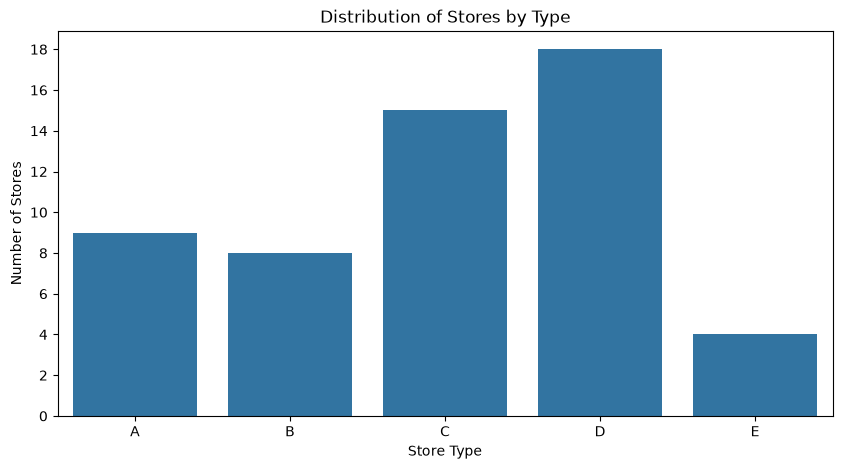

In [74]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=stores_df,
    x="type",
    order=["A", "B", "C", "D", "E"]
)

plt.title("Distribution of Stores by Type")
plt.xlabel("Store Type")
plt.ylabel("Number of Stores")

from matplotlib.ticker import MaxNLocator

plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))

plt.show()

Store types D and C dominate the distribution, accounting for approximately 61% of all 54 stores. Type D is the most common (33.3%), followed by type C (27.8%), while type E is the least represented (7.4%). This indicates an uneven distribution of store types across the retail network.

In [76]:
# Holiday events (he) dataset characteristics
he_path = Path("../data/raw/holidays_events.csv")
he_df = pd.read_csv(he_path)

In [77]:
quick_df_inspection(he_df)

--- Shape of the dataset ---
Dataset contains 350 rows and 6 columns

--- Column names, non-null counts and data types ---
Dataset: columns, non-null counts and data types
<class 'pandas.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   date         350 non-null    str  
 1   type         350 non-null    str  
 2   locale       350 non-null    str  
 3   locale_name  350 non-null    str  
 4   description  350 non-null    str  
 5   transferred  350 non-null    bool 
dtypes: bool(1), str(5)
memory usage: 14.1 KB

--- Count of missing values per column ---
date           0
type           0
locale         0
locale_name    0
description    0
transferred    0
dtype: int64


In [189]:
# Convert date into proper pandas datetime object
he_df["date"] = pd.to_datetime(he_df["date"], errors="coerce")

# Check conversion worked as intended
print(f"'date' column is of type: {he_df['date'].dtype}")

# Check for NaT in 'date' column
he_df["date"].isna().sum()

'date' column is of type: datetime64[us]


np.int64(0)

In [78]:
he_min_date, he_max_date = he_df["date"].min(), he_df["date"].max()
print(f"Earliest date in holidays events dataset: {he_min_date}")
print(f"Latest date in holidays events dataset: {he_max_date}")

Earliest date in holidays events dataset: 2012-03-02
Latest date in holidays events dataset: 2017-12-26


In [79]:
# Distribution of holiday events by types
print("Distribution of holiday events by type")
print()
he_df["type"].value_counts().to_frame()

Distribution of holiday events by type



,count
type,
Holiday,221
Event,56
Additional,51
Transfer,12
Bridge,5
Work Day,5


In [80]:
# Distribution of holiday events by locale
print("Distribution of holiday events by locale")
print()
he_df["locale"].value_counts().to_frame()

Distribution of holiday events by locale



,count
locale,
National,174
Local,152
Regional,24


In [81]:
# Distribution of holiday events by transferred
print("Distribution of holiday events by transferred")
print()
he_df["transferred"].value_counts().to_frame()

Distribution of holiday events by transferred



,count
transferred,
False,338
True,12


In [82]:
# Check whether multiple events can occur on the same date
he_df["date"].duplicated().sum()

np.int64(38)

There are 38 duplicated dates in the dataset.

In [84]:
duplicated_dates = set(he_df[he_df["date"].duplicated()]["date"])
duplicated_dates

{'2012-06-25',
 '2012-07-03',
 '2012-12-22',
 '2012-12-24',
 '2012-12-31',
 '2013-05-12',
 '2013-06-25',
 '2013-07-03',
 '2013-12-22',
 '2014-06-25',
 '2014-07-03',
 '2014-12-22',
 '2014-12-26',
 '2015-06-25',
 '2015-07-03',
 '2015-12-22',
 '2016-04-21',
 '2016-05-01',
 '2016-05-07',
 '2016-05-08',
 '2016-05-12',
 '2016-06-25',
 '2016-07-03',
 '2016-07-24',
 '2016-11-12',
 '2016-12-22',
 '2017-04-14',
 '2017-06-25',
 '2017-07-03',
 '2017-12-08',
 '2017-12-22'}

In [85]:
# Check manually some of the duplicated dates
he_df[he_df["date"] == '2012-06-25']

,date,type,locale,locale_name,description,transferred
7,2012-06-25,Holiday,Regional,Imbabura,Provincializacion de Imbabura,False
8,2012-06-25,Holiday,Local,Latacunga,Cantonizacion de Latacunga,False
9,2012-06-25,Holiday,Local,Machala,Fundacion de Machala,False


In [86]:
# Check manually some of the duplicated dates
he_df[he_df["date"] == '2016-05-12']

,date,type,locale,locale_name,description,transferred
249,2016-05-12,Holiday,Local,Puyo,Cantonizacion del Puyo,False
250,2016-05-12,Event,National,Ecuador,Terremoto Manabi+26,False


Multiple holidays and events can occur on the same date, often affecting different geographic locations or representing different event types. Therefore, date is not a unique identifier in the holidays dataset. Future joins with sales data must account for geographic applicability and multiple events per date to prevent unintended row duplication.

In [88]:
# Verify whether any entire rows are exact duplicates
he_df.duplicated().sum()

np.int64(0)

Holiday event dataset contain no exact duplicate rows.

In [147]:
# Oildataset characteristics
oil_path = Path("../data/raw/oil.csv")
oil_df = pd.read_csv(oil_path)

In [149]:
quick_df_inspection(oil_df)

--- Shape of the dataset ---
Dataset contains 1218 rows and 2 columns

--- Column names, non-null counts and data types ---
Dataset: columns, non-null counts and data types
<class 'pandas.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        1218 non-null   str    
 1   dcoilwtico  1175 non-null   float64
dtypes: float64(1), str(1)
memory usage: 19.2 KB

--- Count of missing values per column ---
date           0
dcoilwtico    43
dtype: int64


Column `dcoilwtico` is missing 43 values (out of 1218 rows, roughly 3.5%)

In [166]:
# Convert date into proper pandas datetime object
oil_df["date"] = pd.to_datetime(oil_df["date"], errors="coerce")

# Check conversion worked as intended
print(f"'date' column is of type: {oil_df['date'].dtype}")

# Check for NaT in 'date' column
oil_df["date"].isna().sum()

'date' column is of type: datetime64[us]


np.int64(0)

In [170]:
oil_min_date, oil_max_date = oil_df["date"].min(), oil_df["date"].max()
print(f"Earliest date in oil dataset: {oil_min_date:%Y-%m-%d}")
print(f"Latest date in oil dataset: {oil_max_date:%Y-%m-%d}")

# Display date difference in days
oil_date_diff_days = (oil_max_date - oil_min_date).days + 1
print(f"Expected calendar days: {oil_date_diff_days}")

# Display number of unique observed dates
oil_unique_dates = oil_df["date"].nunique()
print(f"Observed unique dates in oil dataset: {oil_unique_dates}")

# Display number of days missing (vs expected for the date range)
oil_n_missing_dates = oil_date_diff_days - oil_unique_dates
print(f"Oil dataset is missing {oil_n_missing_dates} days from the calendar range")

Earliest date in oil dataset: 2013-01-01
Latest date in oil dataset: 2017-08-31
Expected calendar days: 1704
Observed unique dates in oil dataset: 1218
Oil dataset is missing 486 days from the calendar range


Oil prices cover January 2013 through August 2017, with observations for 1,218 of 1,704 calendar days. The dataset contains 486 dates without records and 43 additional observations with missing prices. The missing dates are consistent with non-trading days, while missing price values require further inspection before preprocessing.

In [193]:
# Isolate rows wiht missing dcoilwtico
missing_oil_price_rows = oil_df[oil_df["dcoilwtico"].isna()]

# Add a 'day_of_week' column to check what day of the week those missing values correspond to
missing_oil_price_rows["day_of_week"] = missing_oil_price_rows["date"].dt.day_name()

# Check count of day_of_week
print(missing_oil_price_rows["day_of_week"].value_counts())
print()

# Merge with holiday events
missing_oil_price_rows = missing_oil_price_rows.merge(right=he_df[["date", "type", "locale", "description"]], on="date", how="left")
missing_oil_price_rows

day_of_week
Monday       23
Friday        9
Thursday      7
Tuesday       2
Wednesday     2
Name: count, dtype: int64



,date,dcoilwtico,day_of_week,type,locale,description
0,2013-01-01,NaN,Tuesday,Holiday,National,Primer dia del ano
1,2013-01-21,NaN,Monday,NaN,NaN,NaN
2,2013-02-18,NaN,Monday,NaN,NaN,NaN
3,2013-03-29,NaN,Friday,NaN,NaN,NaN
4,2013-05-27,NaN,Monday,NaN,NaN,NaN
5,2013-07-04,NaN,Thursday,NaN,NaN,NaN
6,2013-09-02,NaN,Monday,NaN,NaN,NaN
7,2013-11-28,NaN,Thursday,NaN,NaN,NaN
8,2013-12-25,NaN,Wednesday,Holiday,National,Navidad
9,2014-01-01,NaN,Wednesday,Holiday,National,Primer dia del ano


Missing oil-price observations occur exclusively on weekdays, with Mondays accounting for the largest share. Some dates coincide with Ecuadorian holidays, particularly New Year's Day, Christmas, and Good Friday. However, many missing prices do not correspond to holidays recorded in the local dataset. This pattern is consistent with US market closures and other reporting gaps.